# 00 — Exploring IBM AML HI-Small

**Ticket T01.** Get to know the dataset before building anything on it.

The data is **synthetic**. IBM's AMLworld simulator generates ordinary financial activity between people, companies and banks, then deliberately injects money-laundering schemes. Because the laundering was planted on purpose, every transaction carries a true label. Real bank data almost never comes with ground truth like this.

* `HI-Small_Trans.csv` — one row per transaction, with an `Is Laundering` 0/1 label.
* `HI-Small_Patterns.txt` — the laundering transactions grouped into *attempts*, each tagged with a pattern name (fan-in, cycle, …).

"HI" means a **h**igher **i**llicit ratio (there is also an LI version). "Small" is the smallest of the three sizes.

Setup: put both files in `data/raw/` (see `data/README.md`) and run this notebook from the repo root or from `notebooks/`.

In [1]:
import io
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data" / "raw"
TRANS_PATH = DATA_DIR / "HI-Small_Trans.csv"
PATTERNS_PATH = DATA_DIR / "HI-Small_Patterns.txt"

# The CSV header has two columns both called "Account" (sender, then receiver),
# so we replace the header with explicit snake_case names.
COLUMNS = [
    "timestamp", "from_bank", "from_account", "to_bank", "to_account",
    "amount_received", "receiving_currency", "amount_paid", "payment_currency",
    "payment_format", "is_laundering",
]
DTYPES = {
    # IDs stay strings: bank codes have meaningful leading zeros ("010" != "10").
    "from_bank": "string", "from_account": "string",
    "to_bank": "string", "to_account": "string",
    "amount_received": "float64", "amount_paid": "float64",
    "receiving_currency": "category", "payment_currency": "category",
    "payment_format": "category", "is_laundering": "int8",
}


def read_transactions(source, has_header=True):
    # The patterns file uses the same row format, so both files go through this
    # one parser. Identical parsing is what makes the exact-row join in section 4 safe.
    df = pd.read_csv(source, header=0 if has_header else None, names=COLUMNS, dtype=DTYPES)
    df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y/%m/%d %H:%M")
    # An account is identified by bank + account ID (see section 3 for why).
    df["src"] = df["from_bank"] + "|" + df["from_account"]
    df["dst"] = df["to_bank"] + "|" + df["to_account"]
    return df


tx = read_transactions(TRANS_PATH)
print(f"{len(tx):,} rows, {tx.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
tx.head()

5,078,345 rows, 696 MB in memory


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,receiving_currency,amount_paid,payment_currency,payment_format,is_laundering,src,dst
0,2022-09-01 00:20:00,010,8000EBD30,010,8000EBD30,3697.34,US Dollar,3697.34,US Dollar,Reinvestment,0,010|8000EBD30,010|8000EBD30
1,2022-09-01 00:20:00,03208,8000F4580,001,8000F5340,0.01,US Dollar,0.01,US Dollar,Cheque,0,03208|8000F4580,001|8000F5340
2,2022-09-01 00:00:00,03209,8000F4670,03209,8000F4670,14675.57,US Dollar,14675.57,US Dollar,Reinvestment,0,03209|8000F4670,03209|8000F4670
3,2022-09-01 00:02:00,012,8000F5030,012,8000F5030,2806.97,US Dollar,2806.97,US Dollar,Reinvestment,0,012|8000F5030,012|8000F5030
4,2022-09-01 00:06:00,010,8000F5200,010,8000F5200,36682.97,US Dollar,36682.97,US Dollar,Reinvestment,0,010|8000F5200,010|8000F5200


## 1. Row count, date range, laundering rate

In [2]:
n_rows = len(tx)
n_laundering = int(tx["is_laundering"].sum())
print(f"Rows:            {n_rows:,}")
print(f"Date range:      {tx['timestamp'].min()}  →  {tx['timestamp'].max()}")
print(f"Laundering rows: {n_laundering:,}")
print(f"Laundering rate: {n_laundering / n_rows:.4%}  (about 1 in {n_rows // n_laundering:,})")
print(f"Exact duplicate rows: {tx.duplicated(subset=COLUMNS).sum()}")

Rows:            5,078,345
Date range:      2022-09-01 00:00:00  →  2022-09-18 16:18:00
Laundering rows: 5,177
Laundering rate: 0.1019%  (about 1 in 980)


Exact duplicate rows: 9


In [3]:
daily = (
    tx.groupby(tx["timestamp"].dt.date)["is_laundering"]
    .agg(transactions="size", laundering="sum")
)
daily["laundering_rate"] = (daily["laundering"] / daily["transactions"]).map("{:.2%}".format)
daily.index.name = "date"
daily

,transactions,laundering,laundering_rate
date,,,
2022-09-01,1114921,322,0.03%
2022-09-02,754449,408,0.05%
2022-09-03,207382,391,0.19%
2022-09-04,207430,407,0.20%
2022-09-05,482650,471,0.10%
2022-09-06,482089,531,0.11%
2022-09-07,482751,497,0.10%
2022-09-08,482773,539,0.11%
2022-09-09,654467,514,0.08%


In [4]:
tail = tx[tx["timestamp"] >= "2022-09-11"]
print(f"From 11 Sept onward: {len(tail):,} transactions, {tail['is_laundering'].sum():,} laundering "
      f"({tail['is_laundering'].mean():.0%})")

From 11 Sept onward: 1,108 transactions, 655 laundering (59%)


**What this means**

* The dataset has about **5.08 million transactions** over **18 days** (1–18 September 2022). **5,177** of them are laundering, a rate of about **0.10%**, or **1 in 980**.
* That makes the problem a *needle in a haystack*. A model that labels every transaction "clean" is 99.9% accurate and completely useless. So we will measure performance with **precision** (of the transactions we flag, how many are really laundering) and **recall** (of the real laundering, how much we catch), never accuracy.
* **Normal activity stops on 10 September, but laundering doesn't.** From 11 September onward there are only about 1,100 transactions a day in total, and roughly 59% of them are laundering. The simulator stopped generating ordinary activity but kept finishing the laundering schemes already under way. A model could learn "late date ⇒ laundering", which is a shortcut that would never hold on real data. Any time-based train/test split must take this into account, and date should never be used as a feature.
* The dips on 3–4 and 10 September are weekends. 1 September is unusually busy, probably because the simulation starts that day and a backlog of scheduled payments lands at once.
* The 9 exact duplicate rows are indistinguishable from each other. In real data they could be genuine repeat payments, so we keep them and simply note them.

## 2. Payment formats and currencies

In [5]:
by_format = (
    tx.groupby("payment_format", observed=True)["is_laundering"]
    .agg(transactions="size", laundering="sum")
    .assign(
        laundering_rate=lambda d: d["laundering"] / d["transactions"],
        share_of_all_laundering=lambda d: d["laundering"] / d["laundering"].sum(),
    )
    .sort_values("laundering_rate", ascending=False)
)
by_format.style.format({
    "transactions": "{:,}", "laundering": "{:,}",
    "laundering_rate": "{:.3%}", "share_of_all_laundering": "{:.1%}",
})

,transactions,laundering,laundering_rate,share_of_all_laundering
payment_format,,,,
ACH,"600,797","4,483",0.746%,86.6%
Bitcoin,"146,091",56,0.038%,1.1%
Cash,"490,891",108,0.022%,2.1%
Cheque,"1,864,331",324,0.017%,6.3%
Credit Card,"1,323,324",206,0.016%,4.0%
Reinvestment,"481,056",0,0.000%,0.0%
Wire,"171,855",0,0.000%,0.0%


In [6]:
by_currency = (
    tx.groupby("payment_currency", observed=True)["is_laundering"]
    .agg(transactions="size", laundering="sum")
    .assign(laundering_rate=lambda d: d["laundering"] / d["transactions"])
    .sort_values("transactions", ascending=False)
)
by_currency.style.format({"transactions": "{:,}", "laundering": "{:,}", "laundering_rate": "{:.3%}"})

,transactions,laundering,laundering_rate
payment_currency,,,
US Dollar,"1,895,172","1,912",0.101%
Euro,"1,168,297","1,372",0.117%
Swiss Franc,"234,860",193,0.082%
Yuan,"213,752",184,0.086%
Shekel,"192,184",95,0.049%
Rupee,"190,202",167,0.088%
UK Pound,"180,738",132,0.073%
Yen,"155,209",155,0.100%
Ruble,"155,178",133,0.086%


In [7]:
cross = tx["payment_currency"].astype(str) != tx["receiving_currency"].astype(str)
print(f"Cross-currency transactions: {cross.sum():,} ({cross.mean():.1%}); "
      f"laundering among them: {tx.loc[cross, 'is_laundering'].sum()}")

Cross-currency transactions: 72,170 (1.4%); laundering among them: 0


**What this means**

* A **payment format** is the channel money moves through: ACH (bulk electronic bank transfer), wire, cheque, credit card, cash, Bitcoin, or reinvestment (moving money between your own holdings).
* **ACH dominates.** Its laundering rate is about 0.75%, roughly 20× higher than the next-highest format (Bitcoin), and it carries about **87%** of all laundering. Wire and reinvestment contain no laundering at all. Section 4 explains why: *every* transaction in the named laundering patterns is ACH.
* Real investigators also treat channel as a risk signal: fast, cheap, bulk electronic transfers are attractive for moving money through many accounts quickly. Here, though, the extreme gap is partly a choice the simulator made. Payment format should be one useful feature among many. If a model treats "ACH" as meaning "laundering", it will be easy to fool and will flood investigators with false alerts.
* There are **15 currencies**. US dollars and euros make up about 60% of rows. Most currencies have a laundering rate between 0.07% and 0.12%. The exceptions are **Saudi Riyal** at 0.42% (about 4× the average) and Bitcoin and Shekel at under 0.05%. Currency is a weaker signal than format but not a useless one. A transaction is *cross-currency* when it is paid in one currency and received in another (an FX conversion). About 1.4% of transactions are cross-currency, and **none** of them are laundering. That is another simulator quirk to note rather than learn from.
* Amounts are in different currencies, so they can't be added together directly. "Total volume" in this notebook therefore means a **count of transactions**, not money. Converting to a single currency is a later ticket.

## 3. Accounts and transactions per account

In [8]:
accounts = pd.concat([
    tx[["from_bank", "from_account"]].set_axis(["bank", "account"], axis=1),
    tx[["to_bank", "to_account"]].set_axis(["bank", "account"], axis=1),
]).drop_duplicates()

ids_in_many_banks = accounts.groupby("account")["bank"].nunique().gt(1)
print(f"Distinct accounts (bank + account ID): {len(accounts):,}")
print(f"Distinct account IDs alone:            {accounts['account'].nunique():,}")
print(f"Account IDs that appear at >1 bank:    {ids_in_many_banks.sum()}")
print(f"Distinct banks:                        {accounts['bank'].nunique():,}")

self_transfer = tx["src"] == tx["dst"]
print(f"Self-transfers (same account both sides): {self_transfer.sum():,} ({self_transfer.mean():.1%})")
print(tx.loc[self_transfer, "payment_format"].value_counts().head(3).to_string())

Distinct accounts (bank + account ID): 515,088
Distinct account IDs alone:            515,080
Account IDs that appear at >1 bank:    8
Distinct banks:                        30,528
Self-transfers (same account both sides): 591,212 (11.6%)
payment_format
Reinvestment    481056
ACH              71347
Bitcoin          26317


In [9]:
# Count each transaction once for every account on it; a self-transfer counts once.
tx_per_account = pd.concat([tx["src"], tx.loc[~self_transfer, "dst"]]).value_counts()
tx_per_account.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99, 0.999]).round(1).to_frame("transactions per account")

,transactions per account
count,515088.0
mean,18.6
std,287.4
min,1.0
25%,2.0
50%,4.0
75%,26.0
90%,50.0
99%,115.0
99.9%,180.0


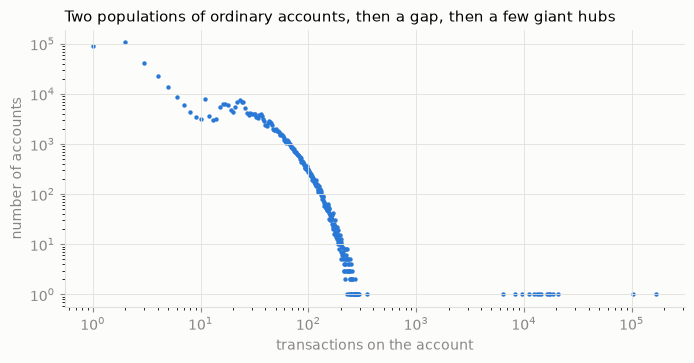

In [10]:
# Single series → one hue, no legend. Log axes because the tail spans 5 orders of magnitude.
SERIES, INK_MUTED, GRID, SURFACE = "#2a78d6", "#898781", "#e1e0d9", "#fcfcfb"

counts = tx_per_account.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.scatter(counts.index, counts.values, s=10, color=SERIES, linewidths=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("transactions on the account", color=INK_MUTED)
ax.set_ylabel("number of accounts", color=INK_MUTED)
ax.set_title("Two populations of ordinary accounts, then a gap, then a few giant hubs", loc="left", fontsize=11)
ax.grid(True, which="major", color=GRID, linewidth=0.6)
ax.tick_params(colors=INK_MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
plt.show()

In [11]:
touches_laundering = pd.concat([
    tx.loc[tx["is_laundering"] == 1, "src"], tx.loc[tx["is_laundering"] == 1, "dst"]
]).unique()
top = tx_per_account.head(10).to_frame("transactions")
top["touches_laundering"] = top.index.isin(touches_laundering)
print(f"Accounts touching ≥1 laundering transaction: {len(touches_laundering):,} "
      f"({len(touches_laundering) / len(accounts):.2%} of accounts)")
top

Accounts touching ≥1 laundering transaction: 6,357 (1.23% of accounts)


,transactions,touches_laundering
070|100428660,169756,True
070|1004286A8,103671,True
070|100428978,20647,True
070|1004286F0,18771,True
070|100428780,17381,True
070|1004289C0,16926,True
070|100428810,16540,True
070|1004287C8,14277,True
070|100428738,13854,True
070|100428A51,13101,True


**What this means**

* There are about **515,000 accounts** across about **30,500 banks**.
* An account is identified by **bank + account ID** together. Eight account IDs appear at more than one bank, so using the account ID alone would merge eight pairs of unrelated accounts into one.
* Activity is extremely uneven. The median account has **4** transactions and 99% have 115 or fewer, while the busiest account (bank 070) has around 170,000. Most accounts appear only a handful of times in 18 days, which leaves very little history to judge them on. The log–log chart shows three separate populations:
  * a large group of near-silent accounts with 1–10 transactions;
  * a second bump of regularly active accounts that peaks around 20–30 transactions and falls off steeply by about 300;
  * after an empty gap (no account has between roughly 350 and 6,000 transactions), a dozen or so giant hubs.

  Real payment networks look smoother. The sharp edges here come from the simulator, but the practical point carries over: "busy" means very different things for different kinds of account.
* The top hubs all sit at **bank 070** and all touch laundering. They look like large intermediary or corporate accounts that thousands of customers pay into, so laundering schemes inevitably route some money through them. That is a reminder that "touched a laundering transaction" is a *transaction* fact, not proof that the account owner is a launderer.
* About 11.6% of transactions are **self-transfers** (same account on both sides), mostly reinvestment. They are bookkeeping, not money changing hands.
* Only about **1.2%** of accounts touch any laundering. For an investigator, the unit of work is usually the **account**, which an alert points to, rather than the individual transaction.

## 4. The patterns file and joining pattern names onto transactions

In [12]:
with open(PATTERNS_PATH) as f:
    for _, line in zip(range(6), f):
        print(line.rstrip())

BEGIN LAUNDERING ATTEMPT - FAN-OUT:  Max 16-degree Fan-Out
2022/09/01 00:06,021174,800737690,012,80011F990,2848.96,Euro,2848.96,Euro,ACH,1
2022/09/01 04:33,021174,800737690,020,80020C5B0,8630.40,Euro,8630.40,Euro,ACH,1
2022/09/01 09:14,021174,800737690,020,80006A5E0,35642.49,Yuan,35642.49,Yuan,ACH,1
2022/09/01 09:56,021174,800737690,00220,8007A5B70,5738987.96,US Dollar,5738987.96,US Dollar,ACH,1
2022/09/01 11:28,021174,800737690,001244,80093C0D0,7254.53,US Dollar,7254.53,US Dollar,ACH,1


The file is a sequence of blocks:

```
BEGIN LAUNDERING ATTEMPT - <PATTERN>[: <detail, e.g. "Max 16-degree Fan-Out">]
<transaction row, same 11 columns as the CSV, no header>
...
END LAUNDERING ATTEMPT - <PATTERN>
```

Each block is one **laundering attempt**: a single scheme made of several linked transactions. The rows carry no ID, so the only way to link them back to the CSV is to match the **whole row**. Below we parse each block, give it an `attempt_id`, and then join.

In [13]:
HEADER_RE = re.compile(r"BEGIN LAUNDERING ATTEMPT - (?P<pattern>[A-Z-]+)(?::\s*(?P<detail>.*))?")


def read_patterns(path):
    rows, attempts = [], []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("END"):
                continue
            if line.startswith("BEGIN"):
                m = HEADER_RE.match(line)
                attempts.append({"attempt_id": len(attempts), "pattern": m["pattern"], "detail": m["detail"] or ""})
            else:
                rows.append((len(attempts) - 1, line))
    attempt_ids, lines = zip(*rows)
    df = read_transactions(io.StringIO("\n".join(lines)), has_header=False)
    df.insert(0, "attempt_id", attempt_ids)
    return df.merge(pd.DataFrame(attempts), on="attempt_id")


patterns = read_patterns(PATTERNS_PATH)
attempt_summary = (
    patterns.groupby("pattern")
    .agg(attempts=("attempt_id", "nunique"), transactions=("attempt_id", "size"))
    .assign(avg_tx_per_attempt=lambda d: (d["transactions"] / d["attempts"]).round(1))
)
print(f"{patterns['attempt_id'].nunique()} attempts, {len(patterns):,} transaction rows, "
      f"labels in file: {patterns['is_laundering'].unique().tolist()}")
attempt_summary

370 attempts, 3,209 transaction rows, labels in file: [1]


,attempts,transactions,avg_tx_per_attempt
pattern,,,
BIPARTITE,49,263,5.4
CYCLE,54,287,5.3
FAN-IN,40,318,8.0
FAN-OUT,48,342,7.1
GATHER-SCATTER,51,716,14.0
RANDOM,41,191,4.7
SCATTER-GATHER,44,626,14.2
STACK,43,466,10.8


In [14]:
JOIN_KEY = COLUMNS[:-1]  # every column except the label

laundering = tx[tx["is_laundering"] == 1]
labelled = laundering.merge(
    patterns[JOIN_KEY + ["attempt_id", "pattern"]], on=JOIN_KEY, how="left", validate="many_to_one"
)
labelled["pattern"] = labelled["pattern"].fillna("UNLISTED")

# Checks on the join itself.
assert len(labelled) == len(laundering), "a laundering row matched more than one pattern row"
assert not patterns.duplicated(JOIN_KEY).any(), "a transaction appears in more than one attempt"
unmatched_pattern_rows = len(patterns.merge(tx[JOIN_KEY], on=JOIN_KEY, how="left", indicator=True)
                             .query("_merge == 'left_only'"))
n_unlisted = (labelled["pattern"] == "UNLISTED").sum()
print(f"Pattern rows with no match in the CSV: {unmatched_pattern_rows}")
print(f"Laundering rows given a pattern:       {len(labelled) - n_unlisted:,} ({1 - n_unlisted / len(labelled):.1%})")
print(f"Laundering rows not in patterns file:  {n_unlisted:,} → 'UNLISTED'")
labelled["pattern"].value_counts().to_frame("laundering transactions")

Pattern rows with no match in the CSV: 0
Laundering rows given a pattern:       3,209 (62.0%)
Laundering rows not in patterns file:  1,968 → 'UNLISTED'


,laundering transactions
pattern,
UNLISTED,1968
GATHER-SCATTER,716
SCATTER-GATHER,626
STACK,466
FAN-OUT,342
FAN-IN,318
CYCLE,287
BIPARTITE,263
RANDOM,191


In [15]:
unlisted = labelled[labelled["pattern"] == "UNLISTED"]
pd.DataFrame({
    "listed": labelled.loc[labelled["pattern"] != "UNLISTED", "payment_format"].value_counts(normalize=True),
    "unlisted": unlisted["payment_format"].value_counts(normalize=True),
}).fillna(0).style.format("{:.1%}")

,listed,unlisted
payment_format,,
ACH,100.0%,64.8%
Bitcoin,0.0%,2.8%
Cash,0.0%,5.5%
Cheque,0.0%,16.5%
Credit Card,0.0%,10.5%


**What this means**

* The file contains **370 attempts** across **8 patterns**, 40–54 attempts each. Each one is a known *typology*, AML's term for a recognisable laundering shape. All 3,209 rows in the file match a laundering transaction in the CSV exactly, and no transaction belongs to more than one attempt, so the join is clean.
* Only about **62%** of laundering transactions have a pattern name. The other **1,968** are labelled laundering in the CSV but do not appear in the patterns file. We tag them `UNLISTED` instead of dropping them. They are real laundering, presumably the simulator's less structured activity (for example the cash, cheque and card movements that bring dirty money into the system).
* The table above shows the clearest difference: **100% of patterned transactions are ACH**, while only about 65% of unlisted ones are. The rest are cheque, credit card, cash and Bitcoin. All the non-ACH laundering in the dataset is unlisted.
* For later work: any feature or explanation that relies on "this belongs to a fan-in" covers only 62% of the positives. The investigation system must still handle laundering that comes with no pattern label.

## 5. Worked examples: fan-in, cycle, scatter-gather

For each typology we pick the first attempt with 4–8 transactions, small enough to read at a glance. Accounts are relabelled **A, B, C…** in order of first appearance so the shape is easy to see. The real IDs are kept in the `src` and `dst` columns.

In [16]:
def show_attempt(pattern, min_rows=4, max_rows=8):
    sizes = patterns[patterns["pattern"] == pattern].groupby("attempt_id").size()
    attempt_id = sizes[sizes.between(min_rows, max_rows)].index[0]
    rows = patterns[patterns["attempt_id"] == attempt_id].sort_values("timestamp")
    order = pd.unique(rows[["src", "dst"]].to_numpy().ravel())
    letter = {acct: chr(ord("A") + i) for i, acct in enumerate(order)}
    detail = rows["detail"].iloc[0]
    print(f"{pattern} — attempt {attempt_id}{' (' + detail + ')' if detail else ''}, {len(rows)} transactions")
    return rows.assign(
        **{"from": rows["src"].map(letter), "to": rows["dst"].map(letter)}
    )[["timestamp", "from", "to", "amount_paid", "payment_currency", "payment_format", "src", "dst"]].reset_index(drop=True)

In [17]:
show_attempt("FAN-IN")

FAN-IN — attempt 105 (Max 5-degree Fan-In), 5 transactions


,timestamp,from,to,amount_paid,payment_currency,payment_format,src,dst
0,2022-09-03 17:21:00,A,B,1161.00,US Dollar,ACH,015|803A52250,019535|80B18E250
1,2022-09-05 19:45:00,C,B,1316.39,US Dollar,ACH,0137888|80DFCA010,019535|80B18E250
2,2022-09-06 08:40:00,D,B,3405.82,US Dollar,ACH,025866|802C6C120,019535|80B18E250
3,2022-09-06 12:52:00,E,B,4109.34,US Dollar,ACH,011974|801998AE0,019535|80B18E250
4,2022-09-07 06:05:00,F,B,10003.75,US Dollar,ACH,0028237|80AD1C820,019535|80B18E250


**Fan-in:** many accounts each send money to **one** collecting account. Read down the `to` column: every row points at B. Here five different senders pay B over four days, all by ACH in US dollars. This is how a launderer *consolidates* money that was spread across mule accounts, or across many small deposits kept under reporting thresholds, back into one place. Seen in isolation each payment looks harmless; the shape only emerges when you look at the receiving account's history.

In [18]:
show_attempt("CYCLE")

CYCLE — attempt 37 (Max 7 hops), 7 transactions


,timestamp,from,to,amount_paid,payment_currency,payment_format,src,dst
0,2022-09-01 18:18:00,A,B,3154.73,US Dollar,ACH,011974|8011D4F20,004503|811A9BD00
1,2022-09-04 07:52:00,C,D,4457.00,Australian Dollar,ACH,0223645|80FBCC760,0028531|80A709C90
2,2022-09-04 08:31:00,D,E,3169.54,US Dollar,ACH,0028531|80A709C90,0132523|80CA77970
3,2022-09-04 16:26:00,F,G,20440.98,Yuan,ACH,0125906|80E11E6A0,014|8035765E0
4,2022-09-04 16:38:00,E,F,3051.99,US Dollar,ACH,0132523|80CA77970,0125906|80E11E6A0
5,2022-09-05 16:25:00,B,C,3154.73,US Dollar,ACH,004503|811A9BD00,0223645|80FBCC760
6,2022-09-05 17:15:00,G,A,3442.53,US Dollar,ACH,014|8035765E0,011974|8011D4F20


**Cycle:** money moves A → B → C → … and finally **back to A**. Follow the letters A → B → C → … → G → A and the chain closes a loop. Note that the timestamps are *not* in hop order (C → D happens before B → C), so the simulator does not always move the money one hop at a time. The amounts drift at each hop rather than staying identical, which makes exact-amount matching unreliable. The point is *layering*: each hop adds distance from the money's origin, and when it returns to its starting account it looks like an ordinary incoming payment. A cycle is invisible from any single account's view. You only see it by following the money across accounts, which is why graph features matter for this problem.

In [19]:
show_attempt("SCATTER-GATHER")

SCATTER-GATHER — attempt 54, 6 transactions


,timestamp,from,to,amount_paid,payment_currency,payment_format,src,dst
0,2022-09-02 08:24:00,A,B,1313989.42,Ruble,ACH,0111631|80A38F130,0016649|80614A030
1,2022-09-02 17:18:00,A,C,4958.17,Euro,ACH,0111631|80A38F130,027920|811B0AE50
2,2022-09-03 13:00:00,A,D,15098.48,Euro,ACH,0111631|80A38F130,016431|8031508A0
3,2022-09-03 13:35:00,B,E,15963.96,Euro,ACH,0016649|80614A030,0010404|807AD0240
4,2022-09-03 16:08:00,C,E,5453.01,Euro,ACH,027920|811B0AE50,0010404|807AD0240
5,2022-09-05 13:31:00,D,E,15098.48,Euro,ACH,016431|8031508A0,0010404|807AD0240


**Scatter-gather:** one source **scatters** money to several intermediaries, and each of them passes it on to a **single** destination. Here A scatters to B, C and D, and all three pass money on to E. D forwards exactly the amount it received (15,098.48). It is a fan-out followed by a fan-in, with the intermediaries acting as a buffer between the source and the destination. The source and destination never transact directly, so a rule that looks only at direct counterparties will miss the link. (Gather-scatter is the reverse: collect first, then distribute.)

## 6. Hard negatives: accounts that look suspicious but are clean

Because amounts mix currencies, "volume" here means **number of distinct counterparties** (tie-broken by transaction count).

* **Candidates:** accounts with **zero** laundering transactions in either direction.
* **Measure:** distinct senders (fan-in shape) and distinct receivers (fan-out shape), with self-transfers excluded.
* **Selection:** we take the **top 3 by distinct senders and the top 2 by distinct receivers**. A single ranking returns five near-identical collector accounts, and hard negatives are more useful when they cover more than one shape.

In [20]:
moves = tx[~self_transfer]
profile = (
    moves.groupby("src").agg(out_tx=("dst", "size"), receivers=("dst", "nunique"), out_laundering=("is_laundering", "sum"))
    .join(moves.groupby("dst").agg(in_tx=("src", "size"), senders=("src", "nunique"), in_laundering=("is_laundering", "sum")),
          how="outer")
    .fillna(0).astype(int)
)
profile["laundering_tx"] = profile["out_laundering"] + profile["in_laundering"]
profile = profile.drop(columns=["out_laundering", "in_laundering"])
profile.index.name = "account"

clean = profile[profile["laundering_tx"] == 0]
fan_in_like = clean.sort_values(["senders", "in_tx"], ascending=False).head(3).assign(shape="fan-in-like")
fan_out_like = (clean.drop(fan_in_like.index)
                .sort_values(["receivers", "out_tx"], ascending=False).head(2).assign(shape="fan-out-like"))
hard_negatives = pd.concat([fan_in_like, fan_out_like])
hard_negatives

,out_tx,receivers,in_tx,senders,laundering_tx,shape
account,,,,,,
021611|8051A3FA0,0,0,94,93,0,fan-in-like
004726|808FAF7C0,0,0,89,89,0,fan-in-like
0014277|80B847A90,0,0,84,84,0,fan-in-like
012|80010F6E0,220,35,1,1,0,fan-out-like
0211|807661E30,223,34,1,1,0,fan-out-like


In [21]:
# How do these compare with real laundering fan-ins / fan-outs?
def max_degree(pattern, side):
    g = patterns[patterns["pattern"] == pattern].groupby(["attempt_id", side])
    return g.size().max()

print(f"Largest FAN-IN collector in the patterns file:  {max_degree('FAN-IN', 'dst')} senders")
print(f"Largest FAN-OUT source in the patterns file:    {max_degree('FAN-OUT', 'src')} receivers")
pct = clean[["senders", "receivers"]].rank(pct=True)
print("Percentile among clean accounts:")
print(pct.loc[hard_negatives.index].round(5).to_string())
assert not hard_negatives.index.isin(pd.concat([patterns["src"], patterns["dst"]])).any()

Largest FAN-IN collector in the patterns file:  16 senders
Largest FAN-OUT source in the patterns file:    16 receivers
Percentile among clean accounts:
                   senders  receivers
account                              
021611|8051A3FA0   1.00000    0.13909
004726|808FAF7C0   1.00000    0.13909
0014277|80B847A90  1.00000    0.13909
012|80010F6E0      0.44691    1.00000
0211|807661E30     0.44691    1.00000


In [22]:
# What each candidate's activity looks like.
def activity(account):
    rows = tx[((tx["src"] == account) | (tx["dst"] == account)) & ~self_transfer]
    return pd.Series({
        "first": rows["timestamp"].min(), "last": rows["timestamp"].max(),
        "formats": ", ".join(rows["payment_format"].value_counts().index[:3].astype(str)),
        "currencies": ", ".join(rows["payment_currency"].value_counts().index[:2].astype(str)),
    })

hard_negatives.index.to_series().apply(activity)

,first,last,formats,currencies
account,,,,
021611|8051A3FA0,2022-09-01 10:30:00,2022-09-09 08:56:00,"ACH, Bitcoin, Cash","US Dollar, Australian Dollar"
004726|808FAF7C0,2022-09-01 22:26:00,2022-09-08 09:59:00,"ACH, Bitcoin, Cash","US Dollar, Australian Dollar"
0014277|80B847A90,2022-09-02 15:00:00,2022-09-02 15:29:00,"ACH, Bitcoin, Cash","Euro, Australian Dollar"
012|80010F6E0,2022-09-01 00:05:00,2022-09-10 22:24:00,"Cheque, Credit Card, ACH","US Dollar, Euro"
0211|807661E30,2022-09-01 00:05:00,2022-09-10 19:13:00,"Cheque, Credit Card, ACH","UK Pound, US Dollar"


**What this means**

* A **hard negative** is a clean account that a naive rule would flag. The three fan-in-like accounts each receive from more than 80 *different* senders, 5–6× the largest fan-in in the laundering patterns (16 senders). The two fan-out-like accounts pay more than 30 different receivers, about twice the largest fan-out (16). On top of that, `0014277|80B847A90` received all 84 of its payments within **29 minutes**: a burst, which is exactly what a real fan-in looks like. On counterparty count alone they look *more* suspicious than the actual launderers.
* In the real world these would be the shop with lots of customers or the company running payroll. **"Many counterparties" is not laundering on its own.** What separates a real fan-in is context: timing (a burst of payments over a few days), how the amounts relate (similar sizes, adding up to an onward transfer), and what happens to the money next.
* We will keep these five (and later, many more chosen by the same rule) as **hard negatives**:
  * For a model, they stop it from learning "high degree ⇒ laundering".
  * For the investigation copilot, they are test cases it must *close as not suspicious* with a sound explanation.
* Caveat: "no label" is reliable here only because the data is synthetic. In real data, unlabelled means *not caught*, not *clean*.

## Checks
These fail loudly if the data or the join drifts from what the findings above describe.

In [23]:
assert n_rows == 5_078_345
assert n_laundering == 5_177
assert patterns["attempt_id"].nunique() == 370 and len(patterns) == 3_209
assert unmatched_pattern_rows == 0
assert len(labelled) == n_laundering
assert n_unlisted == 1_968
assert ids_in_many_banks.sum() == 8
assert len(hard_negatives) == 5 and (hard_negatives["laundering_tx"] == 0).all()
print("All checks passed.")
print(f"rows={n_rows:,} laundering={n_laundering:,} rate={n_laundering / n_rows:.4%} "
      f"attempts=370 pattern_rows=3,209 matched={n_laundering - n_unlisted:,} unlisted={n_unlisted:,} "
      f"unmatched_pattern_rows={unmatched_pattern_rows} hard_negatives={len(hard_negatives)}")

All checks passed.
rows=5,078,345 laundering=5,177 rate=0.1019% attempts=370 pattern_rows=3,209 matched=3,209 unlisted=1,968 unmatched_pattern_rows=0 hard_negatives=5
